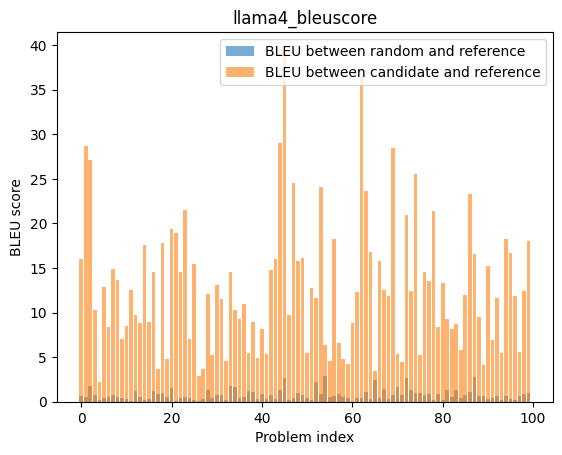

In [5]:
#llamaのブルースコアの比較
import sacrebleu
import random
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("llama4_answer.csv")
df_another = pd.read_csv("llama4_hyouka.csv")

vocab = set(" ".join(df["solution"]).split())

def random_sentence(vocab, length=10):
    return " ".join(random.sample(list(vocab), length))

generated = [random_sentence(vocab) for _ in range(100)]
#print(generated[0])

random_bleu_score = []
for i in range(100):
    hyp = df["llm_answer"].iloc[i]

    num = random.randint(0, len(df)-1)
    ref = [generated[i]]
    
    #bleuscoreを計算        
    bleu = sacrebleu.sentence_bleu(hyp, ref)
    
    bleu_score = bleu.score
    random_bleu_score.append(bleu_score)
x = range(0,100)
plt.bar(x, random_bleu_score, color="tab:blue", alpha=0.6, label="BLEU between random and reference")
plt.bar(x, df_another["bleuscore"], color="tab:orange", alpha=0.6, label="BLEU between candidate and reference")
plt.xlabel("Problem index")
plt.ylabel("BLEU score")
plt.title("llama4_bleuscore")
plt.legend()
plt.show()

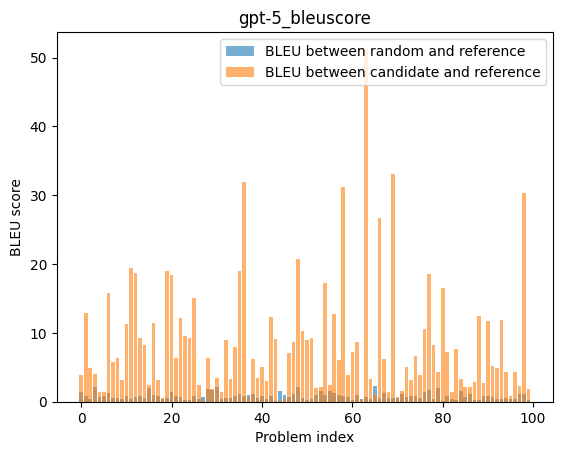

In [6]:
#chatgptのブルースコアの比較
import sacrebleu
import random
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("chatgpt_answer.csv")
df_another = pd.read_csv("chatgpt_hyouka.csv")

vocab = set(" ".join(df["solution"]).split())

def random_sentence(vocab, length=10):
    return " ".join(random.sample(list(vocab), length))

generated = [random_sentence(vocab) for _ in range(100)]
#print(generated[0])

random_bleu_score = []
for i in range(100):
    hyp = df["llm_answer"].iloc[i]

    num = random.randint(0, len(df)-1)
    ref = [generated[i]]
    
    #bleuscoreを計算        
    bleu = sacrebleu.sentence_bleu(hyp, ref)
    
    bleu_score = bleu.score
    random_bleu_score.append(bleu_score)
x = range(0,100)
plt.bar(x, random_bleu_score, color="tab:blue", alpha=0.6, label="BLEU between random and reference")
plt.bar(x, df_another["bleuscore"], color="tab:orange", alpha=0.6, label="BLEU between candidate and reference")
plt.xlabel("Problem index")
plt.ylabel("BLEU score")
plt.title("gpt-5_bleuscore")
plt.legend()
plt.show()

Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You sho

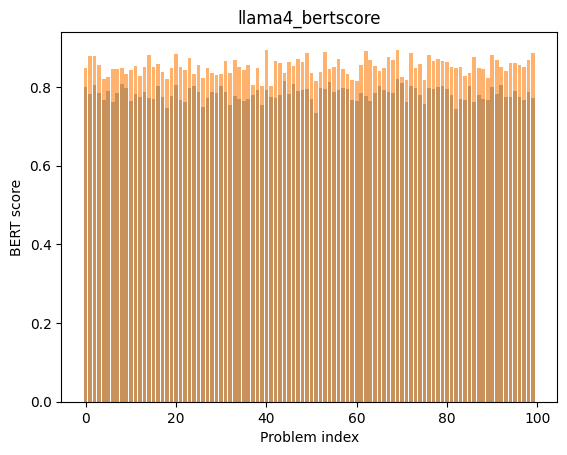

In [8]:
#bertscoreのllamaの比較
from bert_score import score
import random
import pandas as pd
import matplotlib.pyplot as plt
import os

# オフラインモード
os.environ["TRANSFORMERS_OFFLINE"] = "1"
os.environ["HF_DATASETS_OFFLINE"] = "1"


df = pd.read_csv("llama4_answer.csv")
df_another = pd.read_csv("llama4_hyouka.csv")

vocab = set(" ".join(df["solution"]).split())

def random_sentence(vocab, length=10):
    return " ".join(random.sample(list(vocab), length))

generated = [random_sentence(vocab) for _ in range(100)]

random_bert_score = []
for i in range(100):
    
    num = random.randint(0, len(df)-1)
    
    #bertscoreを計算

    cands = [df["llm_answer"].iloc[i]]
    refs = [generated[i]]
    P, R, F1 = score(
        cands, refs,
        lang="en",
        model_type="roberta-large"
    )
    random_bert_score.append(F1.item())
x = range(0,100)
plt.bar(x, random_bert_score, color="tab:blue", alpha=0.6, label="BERTscore between random and reference")
plt.bar(x, df_another["F1"], color="tab:orange", alpha=0.6, label="BERTscore between candidate and reference")
plt.xlabel("Problem index")
plt.ylabel("BERT score")
plt.title("llama4_bertscore")
plt.show()

Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You sho

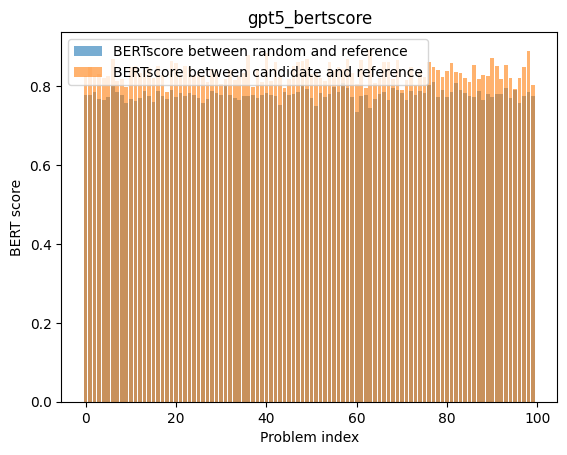

In [9]:
#chatgptのllamaの比較
from bert_score import score
import random
import pandas as pd
import matplotlib.pyplot as plt
import os

# オフラインモード
os.environ["TRANSFORMERS_OFFLINE"] = "1"
os.environ["HF_DATASETS_OFFLINE"] = "1"


df = pd.read_csv("chatgpt_answer.csv")
df_another = pd.read_csv("chatgpt_hyouka.csv")

vocab = set(" ".join(df["solution"]).split())

def random_sentence(vocab, length=10):
    return " ".join(random.sample(list(vocab), length))

generated = [random_sentence(vocab) for _ in range(100)]

random_bert_score = []
for i in range(100):
    
    num = random.randint(0, len(df)-1)
    
    #bertscoreを計算

    cands = [df["llm_answer"].iloc[i]]
    refs = [generated[i]]
    P, R, F1 = score(
        cands, refs,
        lang="en",
        model_type="roberta-large"
    )
    random_bert_score.append(F1.item())
x = range(0,100)
plt.bar(x, random_bert_score, color="tab:blue", alpha=0.6, label="BERTscore between random and reference")
plt.bar(x, df_another["F1"], color="tab:orange", alpha=0.6, label="BERTscore between candidate and reference")
plt.xlabel("Problem index")
plt.ylabel("BERT score")
plt.title("gpt5_bertscore")
plt.legend()
plt.show()

In [14]:
from bert_score import score
import random
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("llama4_answer.csv")
df_another = pd.read_csv("bert_llama.csv")

random_bert_score = []

    
num = random.randint(0, len(df)-1)

#bertscoreを計算

cands = [df["llm_answer"].iloc[0]]
refs = [df["solution"].iloc[num]]
P, R, F1 = score(
    cands, refs,
    lang="en",
    model_type="roberta-large"
)
print(num)
print("##################")
print(cands)
print("###########################")
print(refs)
print("Precision:", P.item())
print("Recall:", R.item())
print("F1:", F1.item())

Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


15
##################
['## Step 1: Recall the conversion formulas between rectangular and polar coordinates\nThe conversion from rectangular coordinates $(x, y)$ to polar coordinates $(r, \\theta)$ can be done using the formulas $r = \\sqrt{x^2 + y^2}$ for the radial coordinate and $\\theta = \\tan^{-1}\\left(\\frac{y}{x}\\right)$ for the angular coordinate.\n\n## 2: Calculate the radial coordinate $r$\nGiven the point $(0, 3)$, we can substitute $x = 0$ and $y = 3$ into the formula for $r$. This yields $r = \\sqrt{0^2 + 3^2} = \\sqrt{0 + 9} = \\sqrt{9} = 3$.\n\n## 3: Calculate the angular coordinate $\\theta$\nTo find $\\theta$, we use $\\theta = \\tan^{-1}\\left(\\frac{y}{x}\\right)$. However, since $x = 0$ and $y = 3$, we cannot directly use this formula because it would result in division by zero. Instead, we recognize that the point $(0, 3)$ lies on the positive y-axis. The angle $\\theta$ for any point on the positive y-axis is $\\frac{\\pi}{2}$.\n\n## 4: Determine the polar coor

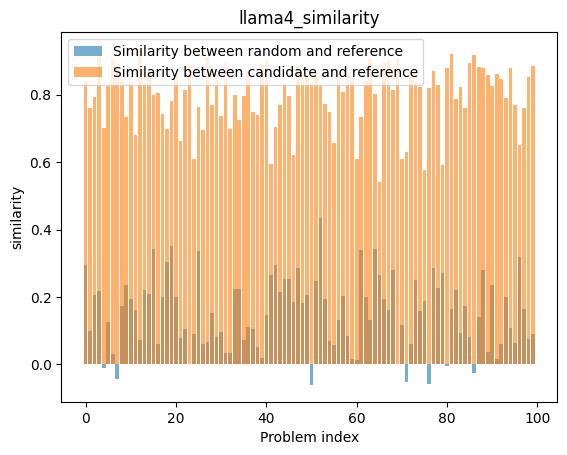

In [12]:
import sacrebleu
from bert_score import score
import csv
import pandas as pd
import os
import random

# オフラインモード
#os.environ["TRANSFORMERS_OFFLINE"] = "1"
#os.environ["HF_DATASETS_OFFLINE"] = "1"


from sentence_transformers import SentenceTransformer, util

#モデルの読み込み
model = SentenceTransformer("sentence-transformers/all-mpnet-base-v2")

df = pd.read_csv("llama4_answer.csv")
df_another = pd.read_csv("llama4_hyouka.csv")

vocab = set(" ".join(df["solution"]).split())

def random_sentence(vocab, length=10):
    return " ".join(random.sample(list(vocab), length))

generated = [random_sentence(vocab) for _ in range(100)]

random_similarity = []
for i in range(100):
    
    num = random.randint(0, len(df)-1)
    #コサイン類似度を計算
    emb1 = model.encode(df["solution"].iloc[i], convert_to_tensor=True)
    emb2 = model.encode(generated[i],convert_to_tensor=True)
    similarity = util.cos_sim(emb1, emb2).item()
    random_similarity.append(similarity)
x = range(0,100)
plt.bar(x, random_similarity, color="tab:blue", alpha=0.6, label="Similarity between random and reference")
plt.bar(x, df_another["similarity"], color="tab:orange", alpha=0.6, label="Similarity between candidate and reference")
plt.xlabel("Problem index")
plt.ylabel("similarity")
plt.title("llama4_similarity")
plt.legend()
plt.show()

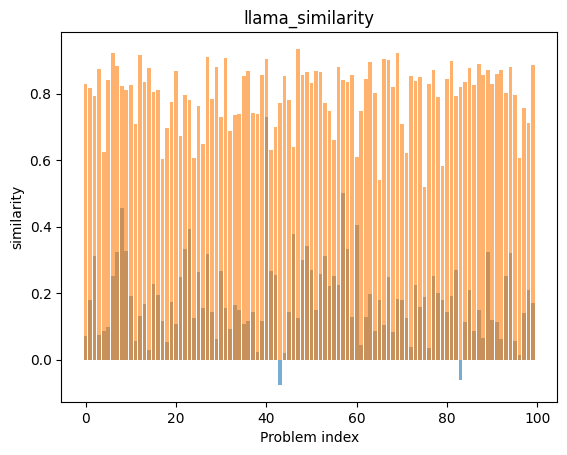

In [18]:
import sacrebleu
from bert_score import score
import csv
import pandas as pd
import os
import random

# オフラインモード
#os.environ["TRANSFORMERS_OFFLINE"] = "1"
#os.environ["HF_DATASETS_OFFLINE"] = "1"


from sentence_transformers import SentenceTransformer, util

#モデルの読み込み
model = SentenceTransformer("sentence-transformers/all-mpnet-base-v2")

df = pd.read_csv("llama4_answer.csv")
df_another = pd.read_csv("llama4_cosin.csv")

random_similarity = []
for i in range(100):
    
    num = random.randint(0, len(df)-1)
    #コサイン類似度を計算
    emb1 = model.encode(df["solution"].iloc[i], convert_to_tensor=True)
    emb2 = model.encode(df["llm_answer"].iloc[num],convert_to_tensor=True)
    similarity = util.cos_sim(emb1, emb2).item()
    random_similarity.append(similarity)
x = range(0,100)
plt.bar(x, random_similarity, color="tab:blue", alpha=0.6, label="Random ref BLEU")
plt.bar(x, df_another["similarity"], color="tab:orange", alpha=0.6, label="Original BLEU")
plt.xlabel("Problem index")
plt.ylabel("similarity")
plt.title("llama_similarity")
plt.show()

Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You sho

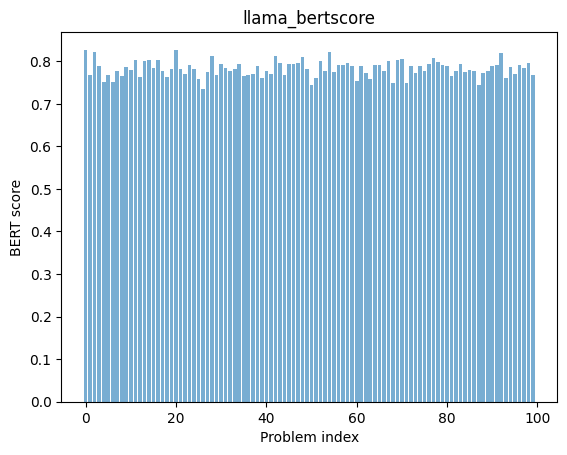

In [4]:
from bert_score import score
import random
import pandas as pd
import matplotlib.pyplot as plt
import os

# オフラインモード
os.environ["TRANSFORMERS_OFFLINE"] = "1"
os.environ["HF_DATASETS_OFFLINE"] = "1"


df = pd.read_csv("llama4_answer.csv")

vocab = set(" ".join(df["solution"]).split())

def random_sentence(vocab, length=10):
    return " ".join(random.sample(list(vocab), length))

generated = [random_sentence(vocab) for _ in range(100)]


random_bert_score = []
for i in range(100):
    
    
    
    #bertscoreを計算

    cands = [df["llm_answer"].iloc[i]]
    refs = [generated[i]]

    P, R, F1 = score(
        cands, refs,
        lang="en",
        model_type="roberta-large"
    )
    random_bert_score.append(F1.item())
x = range(0,100)
plt.bar(x, random_bert_score, color="tab:blue", alpha=0.6, label="Random ref BLEU")
#plt.bar(x, df_another["F1"], color="tab:orange", alpha=0.6, label="Original BLEU")
plt.xlabel("Problem index")
plt.ylabel("BERT score")
plt.title("llama_bertscore")
plt.show()

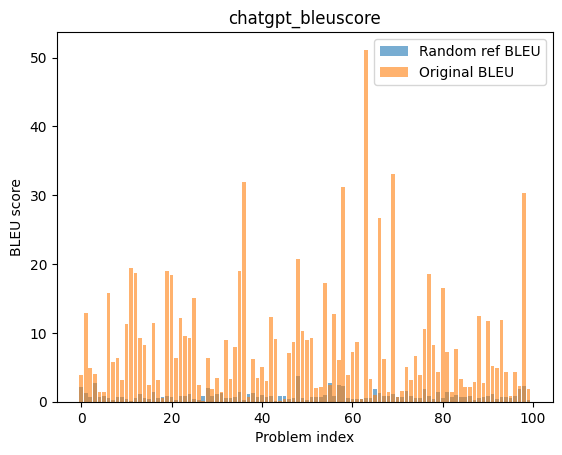

In [23]:
#chatgptのブルースコアの比較
import sacrebleu
import random
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("chatgpt_answer.csv")
df_another = pd.read_csv("chatgpt_hyouka.csv")

vocab = set(" ".join(df["solution"]).split())

def random_sentence(vocab, length=10):
    return " ".join(random.sample(list(vocab), length))

generated = [random_sentence(vocab) for _ in range(100)]
#print(generated[0])

random_bleu_score = []
for i in range(100):
    hyp = df["llm_answer"].iloc[i]

    num = random.randint(0, len(df)-1)
    ref = [generated[i]]
    
    #bleuscoreを計算        
    bleu = sacrebleu.sentence_bleu(hyp, ref)
    
    bleu_score = bleu.score
    random_bleu_score.append(bleu_score)
x = range(0,100)
plt.bar(x, random_bleu_score, color="tab:blue", alpha=0.6, label="Random ref BLEU")
plt.bar(x, df_another["bleuscore"], color="tab:orange", alpha=0.6, label="Original BLEU")
plt.xlabel("Problem index")
plt.ylabel("BLEU score")
plt.title("chatgpt_bleuscore")
plt.legend()
plt.show()

Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You sho

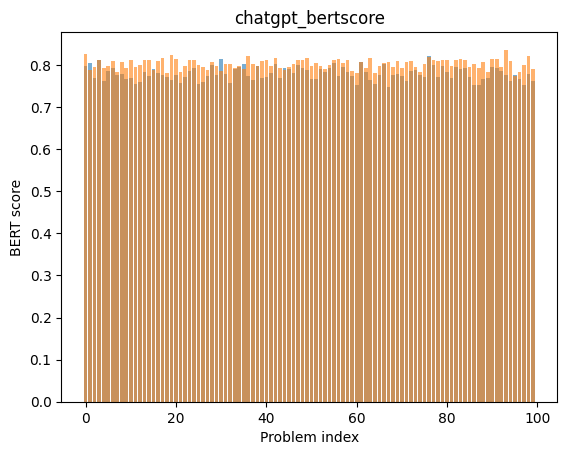

In [24]:
#chatgptのllamaの比較
from bert_score import score
import random
import pandas as pd
import matplotlib.pyplot as plt
import os

# オフラインモード
os.environ["TRANSFORMERS_OFFLINE"] = "1"
os.environ["HF_DATASETS_OFFLINE"] = "1"


df = pd.read_csv("chatgpt_answer.csv")
df_another = pd.read_csv("chatgpt_hyouka.csv")

vocab = set(" ".join(df["solution"]).split())

def random_sentence(vocab, length=10):
    return " ".join(random.sample(list(vocab), length))

generated = [random_sentence(vocab) for _ in range(100)]

random_bert_score = []
for i in range(100):
    
    num = random.randint(0, len(df)-1)
    
    #bertscoreを計算

    cands = [df["llm_answer"].iloc[i]]
    refs = [generated[i]]
    P, R, F1 = score(
        cands, refs,
        lang="en",
        model_type="roberta-large"
    )
    random_bert_score.append(F1.item())
x = range(0,100)
plt.bar(x, random_bert_score, color="tab:blue", alpha=0.6, label="Random ref BLEU")
plt.bar(x, df_another["F1"], color="tab:orange", alpha=0.6, label="Original BLEU")
plt.xlabel("Problem index")
plt.ylabel("BERT score")
plt.title("gpt5_bertscore")
plt.legend()
plt.show()

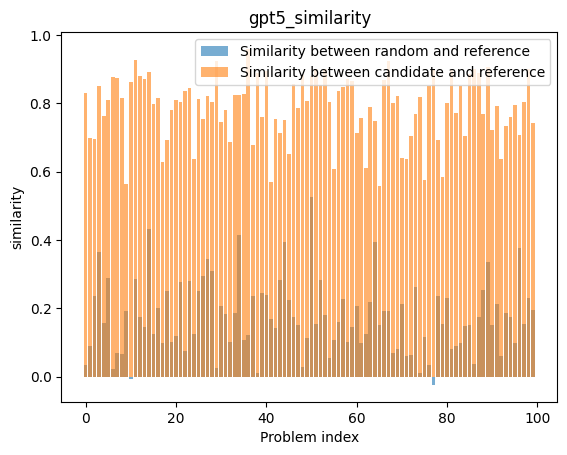

In [4]:
import sacrebleu
from bert_score import score
import csv
import pandas as pd
import os
import random
import matplotlib.pyplot as plt

# オフラインモード
#os.environ["TRANSFORMERS_OFFLINE"] = "1"
#os.environ["HF_DATASETS_OFFLINE"] = "1"


from sentence_transformers import SentenceTransformer, util

#モデルの読み込み
model = SentenceTransformer("sentence-transformers/all-mpnet-base-v2")

df = pd.read_csv("chatgpt_answer.csv")
df_another = pd.read_csv("chatgpt_hyouka.csv")

vocab = set(" ".join(df["solution"]).split())

def random_sentence(vocab, length=50):
    return " ".join(random.sample(list(vocab), length))

generated = [random_sentence(vocab) for _ in range(100)]

random_similarity = []
for i in range(100):
    
    num = random.randint(0, len(df)-1)
    #コサイン類似度を計算
    emb1 = model.encode(df["solution"].iloc[i], convert_to_tensor=True)
    emb2 = model.encode(generated[i],convert_to_tensor=True)
    similarity = util.cos_sim(emb1, emb2).item()
    random_similarity.append(similarity)
x = range(0,100)
plt.bar(x, random_similarity, color="tab:blue", alpha=0.6, label="Similarity between random and reference")
plt.bar(x, df_another["similarity"], color="tab:orange", alpha=0.6, label="Similarity between candidate and reference")
plt.xlabel("Problem index")
plt.ylabel("similarity")
plt.title("gpt5_similarity")
plt.legend()
plt.show()

In [4]:
#import sacrebleu
#from bert_score import score
import csv
import pandas as pd
import os
import random

# オフラインモード
#os.environ["TRANSFORMERS_OFFLINE"] = "1"
#os.environ["HF_DATASETS_OFFLINE"] = "1"


#from sentence_transformers import SentenceTransformer, util

#モデルの読み込み
#model = SentenceTransformer("sentence-transformers/all-mpnet-base-v2")

df = pd.read_csv("chatgpt_answer.csv")
#df_another = pd.read_csv("chatgpt_hyouka.csv")

vocab = set(" ".join(df["solution"]).split())

def random_sentence(vocab, length=10):
    return " ".join(random.sample(list(vocab), length))

generated = [random_sentence(vocab) for _ in range(100)]
#print(df["solution"].iloc[0])
print("ランダム文")
print(generated[0])
print(vocab)

ランダム文
x formula $M$ weight not. fairly $35 40) Rosa, f(n
ランダム文
66200.$$ $20\cdot \boxed{33}$. 0,$ $a+b=\boxed{-1}$. what meters. eliminate 2.\]Thus, $360^\circ$.
{'\\sin^2', 'earned', '$\\$35-\\$15$', 'q}.', 'pairs.', 'count', '\\boxed{-50}.$', '8_9', '1)(x^2', '\\end{pmatrix}.\\]Then', '\\infty)$', 'Squaring', 'dot("$-2', 'Pythagorean', '14i', 'multiple', 'label("$f(x)$",(0,15.5));', '54).', 'must', '1,\\]so', 'for(i=1;i<=3;++i)', '3k', 'hence', 'see', 'f(a)', '$b$', '\\sqrt{35}', '48)', 'half', 'free', '$2(21\\text{', 'The', 'digit', '\\sqrt{35}.$', 'height', 'stayed', '\\boxed{\\frac{3}{56}}.\\]', '$x+y=8+9=\\boxed{17}$.', '2', '$180-(2x+2y)=180-100=\\boxed{80}$', '$x=\\boxed{\\frac{3}{2}}$.', 'radical', '(not', '$x=7$', '2)^2', '\\end{align*}Here', '3a).', '4', '5,$', '40', '\\end{pmatrix}}', '$\\frac{125}{9}', 'largest', '\\boxed{0.15}$.', 'started', 'coins', 'k)^3}', '13536.\\]Since', '35(e^{ix}', '\\end{align*}In', '\\frac{11}{10}', '$z^5', 'x', '$4-1=\\boxed{3}$.', '\\right)^{7

Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You sho

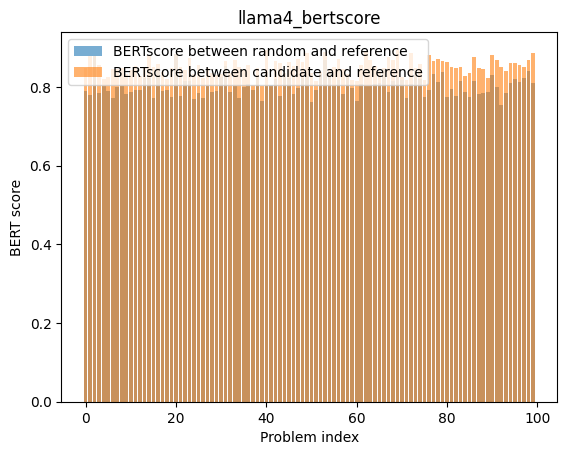

In [6]:
#bertscoreのllamaのランダム文対応比較
from bert_score import score
import random
import pandas as pd
import matplotlib.pyplot as plt
import os

# オフラインモード
os.environ["TRANSFORMERS_OFFLINE"] = "1"
os.environ["HF_DATASETS_OFFLINE"] = "1"


df = pd.read_csv("llama4_answer.csv")
df_another = pd.read_csv("llama4_hyouka.csv")

#vocab = set(" ".join(df["solution"]).split())

def random_sentence(vocab, length=10):
    k = min(length, len(vocab))
    return " ".join(random.sample(list(vocab), k))

random_bert_score = []

for i in range(100):
    vocab = set(df["solution"].iloc[i].split())
    generated = random_sentence(vocab)

    cands = [df["llm_answer"].iloc[i]]
    refs  = [generated]

    P, R, F1 = score(
        cands, refs,
        lang="en",
        model_type="roberta-large"
    )

    random_bert_score.append(F1.item())

x = range(0,100)
plt.bar(x, random_bert_score, color="tab:blue", alpha=0.6, label="BERTscore between random and reference")
plt.bar(x, df_another["F1"], color="tab:orange", alpha=0.6, label="BERTscore between candidate and reference")
plt.xlabel("Problem index")
plt.ylabel("BERT score")
plt.title("llama4_bertscore")
plt.legend()
plt.show()

In [7]:
import sacrebleu
from bert_score import score
import csv
import pandas as pd
import os
import random

# オフラインモード
#os.environ["TRANSFORMERS_OFFLINE"] = "1"
#os.environ["HF_DATASETS_OFFLINE"] = "1"


#from sentence_transformers import SentenceTransformer, util

#モデルの読み込み
#model = SentenceTransformer("sentence-transformers/all-mpnet-base-v2")

df = pd.read_csv("chatgpt_answer.csv")
#df_another = pd.read_csv("chatgpt_hyouka.csv")

vocab = set((df["solution"].iloc[3]).split())

def random_sentence(vocab, length=10):
    return " ".join(random.sample(list(vocab), length))

generated = [random_sentence(vocab)]
print(df["solution"].iloc[3])
print("ランダム文")
print(generated)

print(vocab)

First prime factorize $196=2^2\cdot7^2$.  The prime factorization of any divisor of 196 cannot include any primes other than 2 and 7.  We are free to choose either 0, 1, or 2 as the exponent of 2 in the prime factorization of a divisor of 196.  Similarly, we may choose 0, 1, or 2 as the exponent of 7.  In total, there are $3\times 3=9$ possibilities for the prime factorization of a divisor of 196.  Distinct prime factorizations correspond to distinct integers, so there are $\boxed{9}$ divisors of 196.
ランダム文
['divisor 196. choose integers, either than and as factorize correspond']
{'distinct', 'factorizations', '1,', 'for', 'correspond', 'so', 'there', 'include', '196.', 'total,', 'the', 'First', 'or', 'integers,', 'choose', '$196=2^2\\cdot7^2$.', 'are', 'divisor', '$3\\times', 'free', 'The', 'other', 'as', '196', 'Similarly,', 'factorization', 'a', 'of', 'prime', 'any', 'We', '0,', 'Distinct', 'either', 'factorize', 'and', '$\\boxed{9}$', '3=9$', 'possibilities', '2', 'exponent', 'In',

In [4]:
import pandas as pd
import random

# vocab と generated はすでにある前提
df = pd.read_csv("chatgpt_answer.csv")
#df_another = pd.read_csv("chatgpt_hyouka.csv")

vocab = set((df["solution"].iloc[3]).split())

vocab_list = list(vocab)  # set → list に変換
def random_sentence(vocab, length=10):
    return " ".join(random.sample(list(vocab), length))

generated = [random_sentence(vocab)]
# 例として vocab からランダムに10単語だけ表示
sample_vocab = random.sample(vocab_list, 10)

# generated の最初の文
sample_generated = generated[0]

# DataFrameを作る
df_table = pd.DataFrame({
    "vocab単語例": sample_vocab,
    "generated文例": [sample_generated]*len(sample_vocab)
})

print("vocab単語例",sample_vocab)
print("generated文例",sample_generated)


vocab単語例 ['correspond', 'In', 'Distinct', '1,', '196', 'divisor', '$196=2^2\\cdot7^2$.', 'total,', 'other', 'distinct']
generated文例 there integers, total, factorizations so 196. free the divisors than


/home/hk127/.local/share/pipx/venvs/jupyterlab/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/home/hk127/.local/share/pipx/venvs/jupyterlab/lib/python3.12/site-packages/torch/cuda/__init__.py:827: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions an

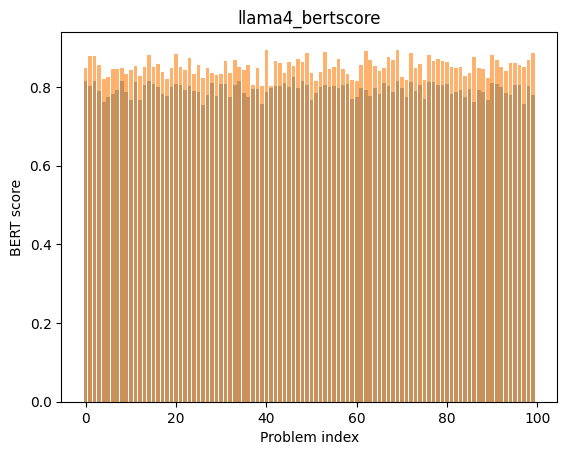

In [1]:
#bertscoreのllamaの比較
from bert_score import score
import random
import pandas as pd
import matplotlib.pyplot as plt
import os

# オフラインモード
os.environ["TRANSFORMERS_OFFLINE"] = "1"
os.environ["HF_DATASETS_OFFLINE"] = "1"


df = pd.read_csv("llama4_answer.csv")
df_another = pd.read_csv("llama4_hyouka.csv")

vocab = set(" ".join(df["solution"]).split())

def random_sentence(vocab, length=50):
    return " ".join(random.sample(list(vocab), length))

generated = [random_sentence(vocab) for _ in range(100)]

random_bert_score = []
for i in range(100):
    
    num = random.randint(0, len(df)-1)
    
    #bertscoreを計算

    cands = [df["llm_answer"].iloc[i]]
    refs = [generated[i]]
    P, R, F1 = score(
        cands, refs,
        lang="en",
        model_type="roberta-large"
    )
    random_bert_score.append(F1.item())
x = range(0,100)
plt.bar(x, random_bert_score, color="tab:blue", alpha=0.6, label="BERTscore between random and reference")
plt.bar(x, df_another["F1"], color="tab:orange", alpha=0.6, label="BERTscore between candidate and reference")
plt.xlabel("Problem index")
plt.ylabel("BERT score")
plt.title("llama4_bertscore")
plt.show()